# Project 18 — Minh họa xử lý ảnh số cho báo cáo giữa kỳ

**Phạm vi:** POC Food-101 10 lớp; minh họa biểu diễn ảnh, hệ màu, biến đổi điểm ảnh/
hình học, lọc nhiễu và nhận dạng cổ điển HOG + SVM; đối chiếu kết quả CNN đã lưu.

Notebook chạy CPU trên **4 ảnh validation**, không tải dữ liệu, không huấn luyện,
không chạy lại Evaluate, không đọc ảnh test và không kết nối database.
Không sửa checkpoint, cấu hình hay pipeline production. Hình minh họa được xuất
PNG 300 dpi; mỗi lần chạy tạo thư mục riêng trong `artifacts/reports/midterm_visualizations/`.

| Đã dùng trong dự án | Chỉ bổ sung trong notebook |
|---|---|
| RGB, ảnh xám cho HOG; sửa EXIF; resize/crop; lật ngang ở training CNN; tensor/ImageNet normalization; HOG/StandardScaler/LinearSVC | HSV/Lab, histogram minh họa, nhiễu nhân tạo, Gaussian/Median Filter, PSNR/MSE/SSIM, hình gradient và HOG |

### Chạy trên Windows 11 / VS Code
1. Mở repository bên trong: `D:\food-recognition-dietary-assistant\food-recognition-dietary-assistant`.
2. Mở notebook này, chọn **Select Kernel → Python Environments → .venv (Python 3.11)**.
   Interpreter: `.venv\Scripts\python.exe` (môi trường CPU hiện có).
3. Chọn **Restart Kernel**, rồi **Run All**. Không cần kích hoạt CUDA, Docker hay PostgreSQL.
4. Nếu một môi trường khác thiếu thư viện, đổi về `.venv`; notebook không tự cài gói.
   Thiếu dataset/artifact thì dừng và báo đúng đường dẫn, không tự tải hay tạo số liệu.
5. Xem danh sách file xuất và kiểm tra cuối notebook. Bản trong `notebooks/notebooks/`
   là bản tương thích đường dẫn ban đầu; dùng bản `notebooks/` làm bản chính khi chỉnh sửa.

In [2]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")
os.environ.setdefault("OMP_NUM_THREADS", "1")
import sys, json, hashlib, platform
from io import BytesIO
from pathlib import Path
from datetime import datetime, timezone
import cv2
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown, Image as NotebookImage
from skimage.feature import hog
from skimage import exposure
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio, structural_similarity
import torch
from torchvision import transforms as T
import joblib

ROOT = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in (base, base / "food-recognition-dietary-assistant")
             if (p / "src/food_assistant/ml/hog_features.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Hãy chạy từ repository hoặc thư mục notebooks bên trong repository.")
sys.path.insert(0, str(ROOT / "src"))
from food_assistant.ml.hog_features import extract_hog
from food_assistant.ml.transforms import build_transform
from food_assistant.services.image_service import ImageService, CropService

cv2.setNumThreads(1)
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 100, "savefig.facecolor": "white"})
SEED = 2026
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

protocol_path = ROOT / "artifacts/reports/poc10-rtx3050-v1/frozen_protocol.json"
protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
releases = {c["model_name"]: ROOT / "artifacts/models" / c["model_name"] / c["run_id"]
            for c in protocol["candidates"]}
protected = [ROOT / "artifacts/production/current.json", ROOT / "configs/hog_svm.yaml",
             ROOT / "src/food_assistant/ml/hog_features.py",
             ROOT / "src/food_assistant/ml/transforms.py"]
protected += [p for directory in releases.values() for p in directory.iterdir()
              if p.is_file() and p.suffix in {".pth", ".joblib", ".json", ".yaml", ".sha256"}]
if (ROOT / ".env").exists():
    protected.append(ROOT / ".env")
before_hashes = {str(p.relative_to(ROOT)): digest(p) for p in protected}
run_id = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
OUT = ROOT / "artifacts/reports/midterm_visualizations" / run_id
OUT.mkdir(parents=True, exist_ok=False)
exported = []
def finish(fig, filename):
    fig.tight_layout()
    target = OUT / filename
    fig.savefig(target, dpi=300, bbox_inches="tight")
    exported.append(str(target.relative_to(ROOT)))
    preview = BytesIO()
    fig.savefig(preview, format="png", dpi=100, bbox_inches="tight")
    display(NotebookImage(data=preview.getvalue()))
    plt.close(fig)

print("Python:", platform.python_version(), "| Interpreter:", sys.executable)
print("Thiết bị: CPU; không tải trọng số hoặc thực hiện training.")
print("Thư mục hình:", OUT.relative_to(ROOT))

Python: 3.11.0 | Interpreter: d:\food-recognition-dietary-assistant\food-recognition-dietary-assistant\.venv\Scripts\python.exe
Thiết bị: CPU; không tải trọng số hoặc thực hiện training.
Thư mục hình: artifacts\reports\midterm_visualizations\run_20261031T150720_680002Z


## Chọn dữ liệu minh họa có kiểm soát
Chọn cố định một ảnh validation mỗi lớp hamburger, ice cream, pizza và chicken curry.
Hamburger dùng ID `hamburger/1010695`, đã xem thủ công để minh họa món ăn thật:
ảnh đầu tiên theo đường dẫn là tượng quảng cáo, không dùng làm ảnh minh họa chính.
Ba lớp còn lại chọn ảnh đầu theo đường dẫn sắp xếp. Lựa chọn chỉ dựa trên nội dung
ảnh phục vụ trình bày, không dựa trên dự đoán/metric của mô hình.
Notebook chỉ giải mã và hash **4 ảnh được chọn**; không quét/đọc ảnh test.
Đối chiếu nhãn, split và checksum với manifest. Đây là ảnh minh họa, không phải tập
thực nghiệm mới để báo cáo accuracy hoặc điều chỉnh siêu tham số.

,image_id,class_key,split,relative_path
0,hamburger/1010695,hamburger,val,images/hamburger/1010695.jpg
1,ice_cream/102595,ice_cream,val,images/ice_cream/102595.jpg
2,pizza/1040878,pizza,val,images/pizza/1040878.jpg
3,chicken_curry/104874,chicken_curry,val,images/chicken_curry/104874.jpg


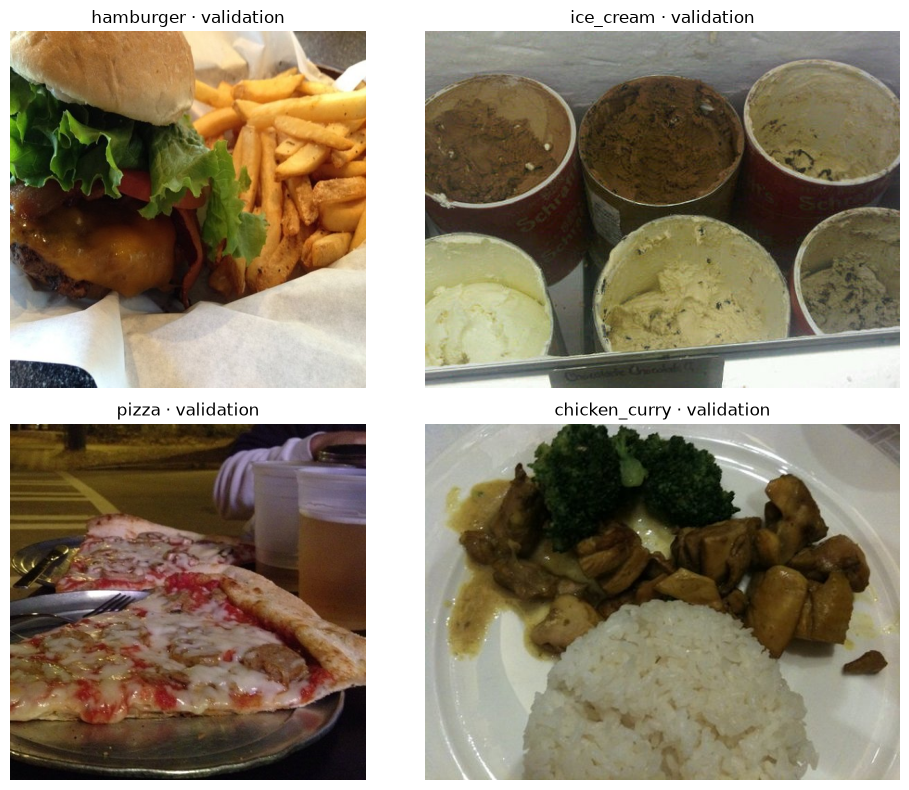

In [3]:
manifest_dir = ROOT / "data/splits/v1"
manifest = pd.read_csv(manifest_dir / "dataset_manifest.csv", keep_default_na=False)
metadata = json.loads((manifest_dir / "dataset_metadata.json").read_text(encoding="utf-8"))
dataset_root = Path(metadata["root"])
if not dataset_root.is_dir():
    dataset_root = ROOT / "data/raw/food-101"
if not dataset_root.is_dir():
    raise FileNotFoundError("Không có Food-101 cục bộ. Notebook không tự tải dataset.")
classes = ["hamburger", "ice_cream", "pizza", "chicken_curry"]
selected = []
for key in classes:
    candidates = manifest[(manifest.class_key == key) & (manifest.split == "val")]
    if key == "hamburger":
        candidates = candidates[candidates.image_id == "hamburger/1010695"]
    if candidates.empty:
        raise ValueError(f"Không có ảnh validation cho {key}")
    selected.append(candidates.sort_values("relative_path").iloc[0].to_dict())
samples = []
for row in selected:
    path = (dataset_root / row["relative_path"]).resolve()
    assert path.is_relative_to(dataset_root.resolve()) and row["split"] == "val"
    assert digest(path) == row["checksum"], "Checksum ảnh minh họa không khớp manifest"
    rgb_image = np.array(ImageService().validate_and_decode(path.read_bytes(), "image/jpeg"))
    samples.append({**row, "rgb": rgb_image})
display(pd.DataFrame([{k: s[k] for k in ("image_id", "class_key", "split", "relative_path")}
                       for s in samples]))
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, sample in zip(axes.flat, samples):
    ax.imshow(sample["rgb"])
    ax.set_title(f"{sample['class_key']} · validation")
    ax.axis("off")
finish(fig, "01_anh_validation.png")
rgb = samples[0]["rgb"]

## 1. Biểu diễn ảnh và hệ màu
**Mục tiêu:** hiểu ảnh là ma trận NumPy `H × W × C`, kiểu `uint8`, mỗi kênh
có mức 0–255. Pipeline giải mã bằng Pillow, sửa EXIF rồi chuyển RGB. Nếu dùng
`cv2.imread`, thứ tự mặc định là **BGR**, cần đổi BGR → RGB trước khi vẽ Matplotlib.

Ảnh xám nén thông tin sáng về một kênh và được dùng thực tế cho HOG; đổi lại mất
phân biệt màu. HSV tách sắc độ/bão hòa/độ sáng, có thể hỗ trợ thao tác theo màu.
Lab tách độ sáng và hai trục đối màu; chỉ minh họa, **chưa dùng trong nhận diện**.
Không hiển thị trực tiếp ma trận HSV/Lab như thể nó là RGB.

Ảnh RGB: shape=(512, 512, 3), dtype=uint8, miền=[0, 255]
Ma trận RGB 2×2 pixel đầu tiên:
 [[[242 241 211]
  [233 230 199]]

 [[231 228 197]
  [229 224 192]]]
Ảnh xám: (512, 512) | HSV/Lab: (512, 512, 3) (512, 512, 3)


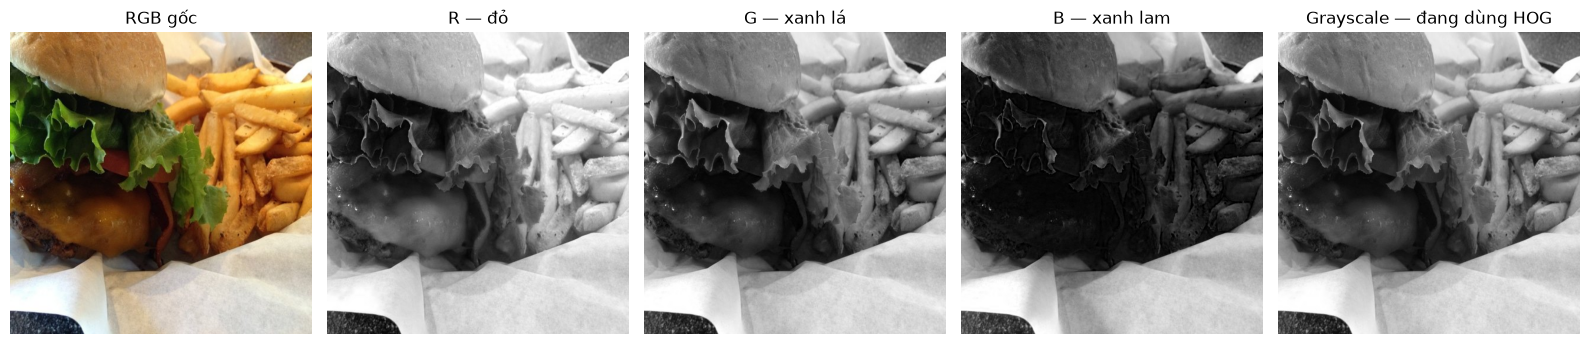

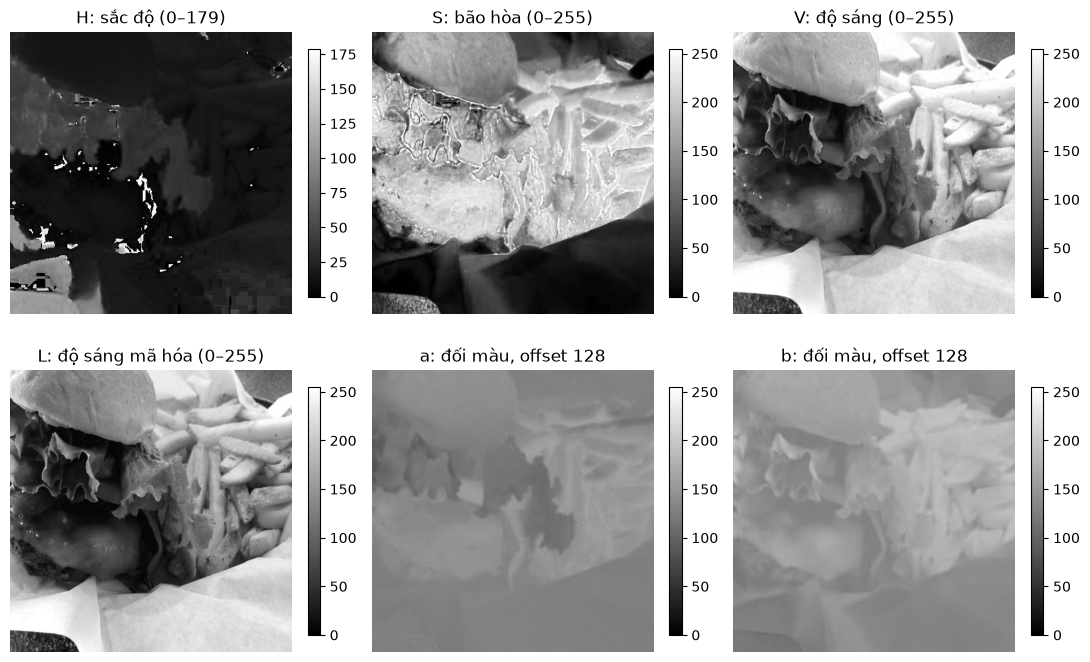

In [4]:
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
print(f"Ảnh RGB: shape={rgb.shape}, dtype={rgb.dtype}, miền=[{rgb.min()}, {rgb.max()}]")
print("Ma trận RGB 2×2 pixel đầu tiên:\n", rgb[:2, :2])
print("Ảnh xám:", gray.shape, "| HSV/Lab:", hsv.shape, lab.shape)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
axes[0].imshow(rgb); axes[0].set_title("RGB gốc")
for ax, index, label in zip(axes[1:4], range(3), ["R — đỏ", "G — xanh lá", "B — xanh lam"]):
    ax.imshow(rgb[..., index], cmap="gray", vmin=0, vmax=255); ax.set_title(label)
axes[4].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[4].set_title("Grayscale — đang dùng HOG")
for ax in axes: ax.axis("off")
finish(fig, "02_rgb_va_kenh_mau.png")

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
labels = ["H: sắc độ (0–179)", "S: bão hòa (0–255)", "V: độ sáng (0–255)",
          "L: độ sáng mã hóa (0–255)", "a: đối màu, offset 128", "b: đối màu, offset 128"]
for ax, layer, label, maximum in zip(axes.flat,
    [hsv[..., i] for i in range(3)] + [lab[..., i] for i in range(3)], labels,
    [179, 255, 255, 255, 255, 255]):
    plotted = ax.imshow(layer, cmap="gray", vmin=0, vmax=maximum)
    ax.set_title(label); ax.axis("off"); fig.colorbar(plotted, ax=ax, fraction=.04)
finish(fig, "03_hsv_lab_tung_kenh.png")

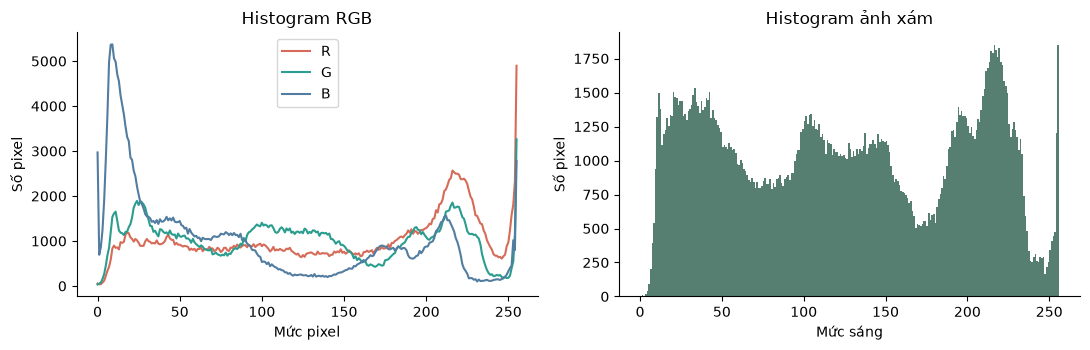

**Nhận xét:** kênh nào sáng hơn chỉ có nghĩa giá trị kênh đó lớn hơn tại vùng ảnh. Histogram biểu diễn phân bố mức pixel, không giữ vị trí không gian và không tự phân đoạn món ăn. OpenCV mã hóa Lab uint8: L xấp xỉ L*×255/100; a/b cộng offset 128. H của HSV 8-bit dùng 0–179, không phải 0–360.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for i, color, label in zip(range(3), ["#d66b59", "#2a9d8f", "#527da0"], ["R", "G", "B"]):
    hist = np.bincount(rgb[..., i].ravel(), minlength=256)
    axes[0].plot(np.arange(256), hist, color=color, label=label)
axes[0].set(title="Histogram RGB", xlabel="Mức pixel", ylabel="Số pixel")
axes[0].legend()
axes[1].hist(gray.ravel(), bins=np.arange(257), color="#567f71")
axes[1].set(title="Histogram ảnh xám", xlabel="Mức sáng", ylabel="Số pixel")
finish(fig, "04_histogram.png")
display(Markdown("**Nhận xét:** kênh nào sáng hơn chỉ có nghĩa giá trị kênh đó lớn hơn tại vùng ảnh. "
    "Histogram biểu diễn phân bố mức pixel, không giữ vị trí không gian và không tự phân đoạn món ăn. "
    "OpenCV mã hóa Lab uint8: L xấp xỉ L*×255/100; a/b cộng offset 128. "
    "H của HSV 8-bit dùng 0–179, không phải 0–360."))

## 2. Thao tác điểm ảnh và biến đổi hình học
**Mục tiêu:** đối chiếu đúng cấu hình đã lưu, không thay đổi tiền xử lý mô hình.
HOG dùng ảnh xám resize thẳng `128 × 128` bằng `INTER_AREA`. CNN validation/inference
resize **cạnh ngắn 256, giữ tỷ lệ**, rồi center-crop `224 × 224`; không phải ép mọi
ảnh thành 224 × 224 ngay từ đầu. ResNet18 dùng bilinear; EfficientNet-B0 dùng bicubic.

Crop thủ công dùng lại `CropService`; lật ngang minh họa phép biến đổi có trong
augmentation training CNN, **không phải bước inference ngẫu nhiên**.
`ToTensor` với uint8: x/255, HWC → CHW. `Normalize`: (x − mean)/std từng kênh.

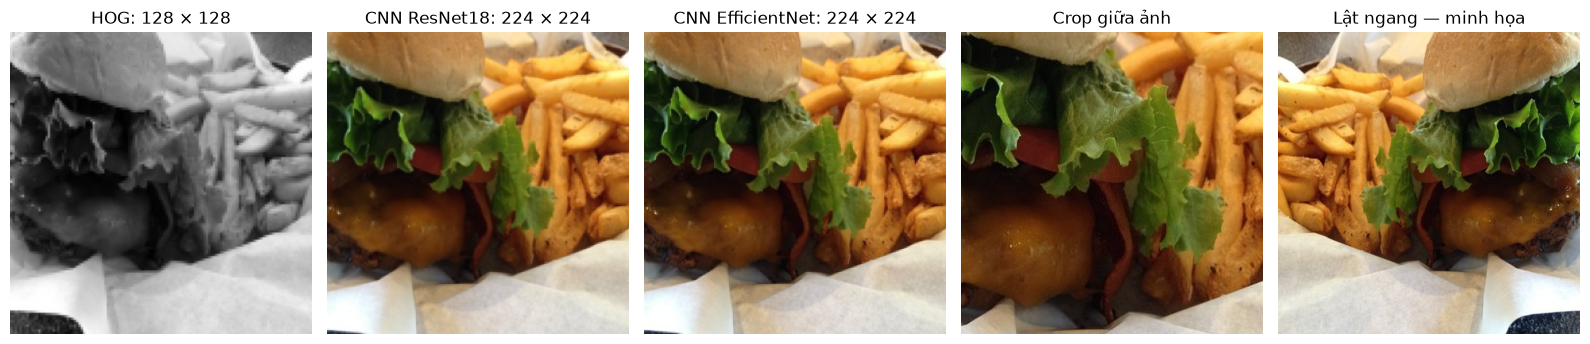

In [6]:
hog_dir = releases["hog_svm"]
hog_config = json.loads((hog_dir / "preprocessing.json").read_text(encoding="utf-8"))
cnn_configs = {name: json.loads((releases[name] / "preprocessing.json").read_text(encoding="utf-8"))
               for name in ("resnet18", "efficientnet_b0")}
assert hog_config["image_size"] == [128, 128]
assert hog_config["hog"] == {"orientations": 9, "pixels_per_cell": [8, 8], "cells_per_block": [2, 2]}
resized_hog = cv2.resize(gray, tuple(hog_config["image_size"]), interpolation=cv2.INTER_AREA)
photo = Image.fromarray(rgb)
cropped = np.array(CropService.crop(photo, [.2, .2, .8, .8]))
flipped = cv2.flip(rgb, 1)
cnn_inputs, cnn_spatial = {}, {}
for name, config in cnn_configs.items():
    transform = build_transform(config, train=False)
    cnn_spatial[name] = np.array(T.Compose(transform.transforms[:2])(photo))
    tensor = transform(photo)
    expected = (np.moveaxis(cnn_spatial[name].astype(np.float32) / 255., -1, 0)
                - np.array(config["mean"], dtype=np.float32)[:, None, None])
    expected /= np.array(config["std"], dtype=np.float32)[:, None, None]
    np.testing.assert_allclose(tensor.numpy(), expected, atol=1e-6)
    assert tuple(tensor.shape) == (3, 224, 224)
    cnn_inputs[name] = tensor
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
examples = [(resized_hog, "HOG: 128 × 128", "gray"),
            (cnn_spatial["resnet18"], "CNN ResNet18: 224 × 224", None),
            (cnn_spatial["efficientnet_b0"], "CNN EfficientNet: 224 × 224", None),
            (cropped, "Crop giữa ảnh", None), (flipped, "Lật ngang — minh họa", None)]
for ax, (array, title, cmap) in zip(axes, examples):
    ax.imshow(array, cmap=cmap); ax.set_title(title); ax.axis("off")
finish(fig, "05_bien_doi_hinh_hoc.png")

uint8: uint8 0 255
float [0,1]: float32 0.0 1.0
Tensor chuẩn hóa: CHW (3, 224, 224) | min/max -2.1179039478302 2.640000104904175


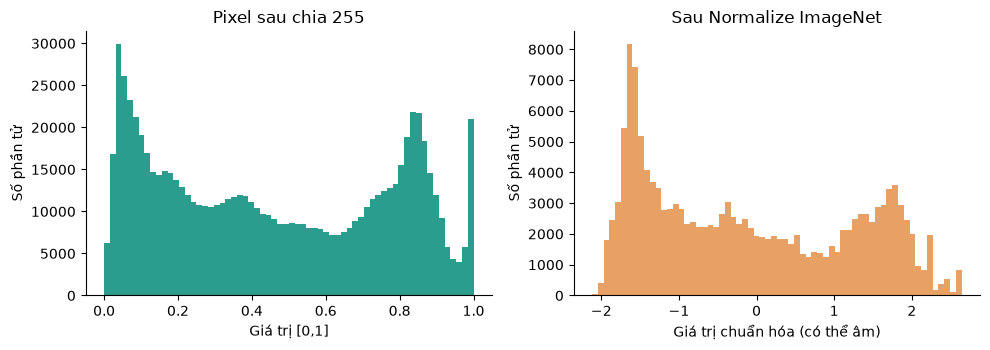

**Nhận xét:** chuẩn hóa ImageNet không giới hạn kết quả trong [0,1]. Không vẽ tensor này như ảnh RGB mà chưa hoàn nguyên. StandardScaler của SVM xử lý từng chiều vector HOG theo mean/std học từ tập train; không chuẩn hóa trực tiếp các kênh ảnh. Các phép hình học ở đây có thể thay đổi bố cục hoặc cắt mất chi tiết món ăn.

In [7]:
float_rgb = rgb.astype(np.float32) / 255.
normalized = cnn_inputs["efficientnet_b0"]
print("uint8:", rgb.dtype, int(rgb.min()), int(rgb.max()))
print("float [0,1]:", float_rgb.dtype, float(float_rgb.min()), float(float_rgb.max()))
print("Tensor chuẩn hóa: CHW", tuple(normalized.shape),
      "| min/max", float(normalized.min()), float(normalized.max()))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(float_rgb.ravel(), bins=64, color="#2a9d8f")
axes[0].set(title="Pixel sau chia 255", xlabel="Giá trị [0,1]", ylabel="Số phần tử")
axes[1].hist(normalized.numpy().ravel(), bins=64, color="#e8a165")
axes[1].set(title="Sau Normalize ImageNet", xlabel="Giá trị chuẩn hóa (có thể âm)", ylabel="Số phần tử")
finish(fig, "06_chuan_hoa_pixel.png")
display(Markdown("**Nhận xét:** chuẩn hóa ImageNet không giới hạn kết quả trong [0,1]. "
    "Không vẽ tensor này như ảnh RGB mà chưa hoàn nguyên. StandardScaler của SVM xử lý "
    "từng chiều vector HOG theo mean/std học từ tập train; không chuẩn hóa trực tiếp các kênh ảnh. "
    "Các phép hình học ở đây có thể thay đổi bố cục hoặc cắt mất chi tiết món ăn."))

## 3. Thí nghiệm lọc ảnh và khử nhiễu độc lập
**Mục tiêu:** tạo nhiễu biết trước để đo sai khác so với ảnh tham chiếu.
Dùng ảnh validation đầu tiên, thu nhỏ cạnh dài tối đa 384 pixel để thí nghiệm nhanh,
giữ tỷ lệ; mọi ảnh trước/sau trong phần này có cùng kích thước và cùng ảnh tham chiếu.

Gaussian noise cộng nhiễu chuẩn với σ = 0,08 trên miền [0,1]. Salt-and-Pepper thay
8% vị trí bằng trắng/đen (xác suất bằng nhau), dùng chung vị trí cho ba kênh.
Gaussian Filter 5×5, σ=1 làm trơn lân cận; Median Filter 5×5 loại điểm ngoại lai.
Mọi cấu hình và seed cố định, không dò tham số bằng tập test.
MSE thấp hơn tốt hơn; PSNR/SSIM cao hơn tốt hơn. Ảnh gốc là ảnh tham chiếu cho
**nhiễu nhân tạo**, không được coi là ảnh sạch tuyệt đối của cảnh thực.

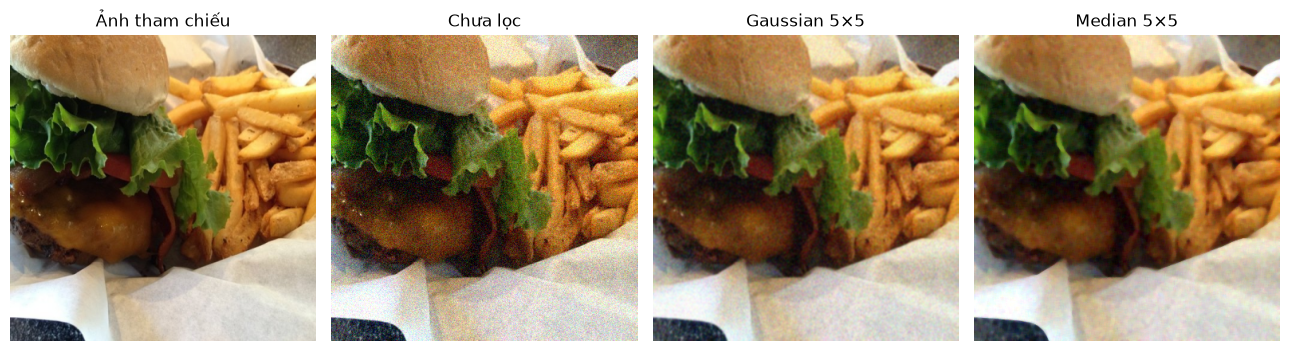

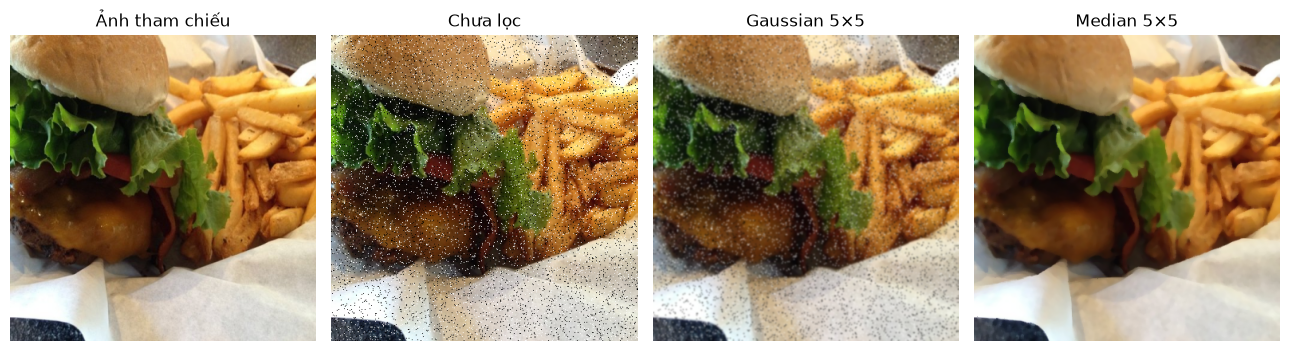

,Loại nhiễu,Phương pháp,MSE,PSNR (dB),SSIM
0,Gaussian,Chưa lọc,373.7639,22.4048,0.3702
1,Gaussian,Gaussian 5×5,55.8240,30.6626,0.7943
2,Gaussian,Median 5×5,62.9054,30.1439,0.7752
3,Salt-and-Pepper,Chưa lọc,1816.1238,15.5393,0.2203
4,Salt-and-Pepper,Gaussian 5×5,215.9467,24.7873,0.5510
5,Salt-and-Pepper,Median 5×5,32.3525,33.0317,0.9032


In [8]:
h, w = rgb.shape[:2]
scale = min(1., 384 / max(h, w))
reference = cv2.resize(rgb, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
def gaussian_noise(image, seed=SEED):
    rng = np.random.default_rng(seed)
    noisy = image.astype(np.float64) / 255. + rng.normal(0, .08, image.shape)
    return np.rint(np.clip(noisy, 0, 1) * 255).astype(np.uint8)
def impulse_noise(image, seed=SEED + 1):
    rng = np.random.default_rng(seed)
    mask = rng.random(image.shape[:2])
    noisy = image.copy()
    noisy[mask < .04] = 0
    noisy[mask >= .96] = 255
    return noisy
noisy_versions = {"Gaussian": gaussian_noise(reference), "Salt-and-Pepper": impulse_noise(reference)}
assert np.array_equal(gaussian_noise(reference), noisy_versions["Gaussian"])
assert np.array_equal(impulse_noise(reference), noisy_versions["Salt-and-Pepper"])
measurements = []
for noise_name, noisy in noisy_versions.items():
    variants = {"Chưa lọc": noisy,
                "Gaussian 5×5": cv2.GaussianBlur(noisy, (5, 5), sigmaX=1),
                "Median 5×5": cv2.medianBlur(noisy, 5)}
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
    for ax, (label, array) in zip(axes, [("Ảnh tham chiếu", reference), *variants.items()]):
        ax.imshow(array); ax.set_title(label); ax.axis("off")
    finish(fig, "07_nhieu_gaussian.png" if noise_name == "Gaussian" else "08_nhieu_salt_pepper.png")
    for label, array in variants.items():
        measurements.append({"Loại nhiễu": noise_name, "Phương pháp": label,
            "MSE": mean_squared_error(reference, array),
            "PSNR (dB)": peak_signal_noise_ratio(reference, array, data_range=255),
            "SSIM": structural_similarity(reference, array, channel_axis=-1, data_range=255)})
noise_metrics = pd.DataFrame(measurements)
assert np.isfinite(noise_metrics[["MSE", "PSNR (dB)", "SSIM"]].to_numpy()).all()
display(noise_metrics.round(4))
noise_metrics.to_csv(OUT / "noise_metrics.csv", index=False, encoding="utf-8-sig")

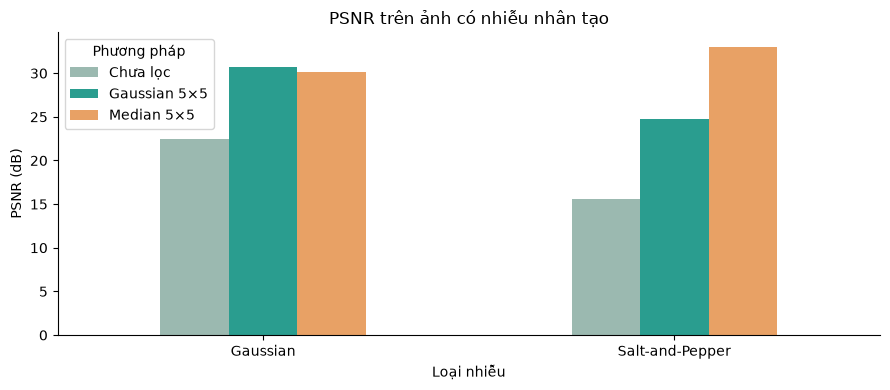

**Gaussian:** PSNR cao nhất trong cấu hình đã thử: Gaussian 5×5 (30.66 dB; chênh +8.26 dB so với chưa lọc).

**Salt-and-Pepper:** PSNR cao nhất trong cấu hình đã thử: Median 5×5 (33.03 dB; chênh +17.49 dB so với chưa lọc).

**Nhận xét:** Gaussian làm giảm biến động nhiễu cộng nhưng có thể làm mờ biên/kết cấu; Median thường phù hợp nhiễu xung salt-and-pepper vì ít chịu ảnh hưởng điểm trắng/đen ngoại lai. Cửa sổ lớn vẫn có thể xóa chi tiết nhỏ. Đối chiếu cả ảnh, SSIM và MSE; thứ hạng trên một ảnh không chứng minh bộ lọc nào luôn tốt nhất hoặc làm tăng accuracy nhận diện. Không có bộ lọc nào trong phần này được chèn vào production.

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
noise_metrics.pivot(index="Loại nhiễu", columns="Phương pháp", values="PSNR (dB)").plot.bar(
    ax=ax, color=["#9bb9b0", "#2a9d8f", "#e8a165"], rot=0)
ax.set(title="PSNR trên ảnh có nhiễu nhân tạo", ylabel="PSNR (dB)", xlabel="Loại nhiễu")
ax.legend(title="Phương pháp")
finish(fig, "09_so_sanh_psnr.png")
for noise_name, group in noise_metrics.groupby("Loại nhiễu"):
    best = group.loc[group["PSNR (dB)"].idxmax()]
    base = group[group["Phương pháp"] == "Chưa lọc"].iloc[0]
    display(Markdown(f"**{noise_name}:** PSNR cao nhất trong cấu hình đã thử: "
        f"{best['Phương pháp']} ({best['PSNR (dB)']:.2f} dB; "
        f"chênh {best['PSNR (dB)'] - base['PSNR (dB)']:+.2f} dB so với chưa lọc)."))
display(Markdown("**Nhận xét:** Gaussian làm giảm biến động nhiễu cộng nhưng có thể làm mờ biên/kết cấu; "
    "Median thường phù hợp nhiễu xung salt-and-pepper vì ít chịu ảnh hưởng điểm trắng/đen ngoại lai. "
    "Cửa sổ lớn vẫn có thể xóa chi tiết nhỏ. Đối chiếu cả ảnh, SSIM và MSE; "
    "thứ hạng trên một ảnh không chứng minh bộ lọc nào luôn tốt nhất hoặc làm tăng accuracy nhận diện. "
    "Không có bộ lọc nào trong phần này được chèn vào production."))

## 4. Trích xuất đặc trưng HOG đúng pipeline đã huấn luyện
**Mục tiêu:** trực quan hóa đặc trưng thủ công được SVM sử dụng.
Gradient biểu diễn hướng/mức thay đổi độ sáng cục bộ. HOG gom phiếu theo **9 hướng**
trong **cell 8×8**, ghép **block 2×2 cell**, chuẩn hóa **L2-Hys** để giảm nhạy với
tương phản cục bộ, rồi nối thành vector. HOG vẫn nhạy với bố cục, nền và biến dạng món.

Gọi lại `extract_hog` thật. Bản `visualize=True` dùng đúng ảnh xám resize, các tham số
và mặc định tương đương; kiểm tra hai vector bằng nhau. Hình HOG được rescale riêng
để dễ quan sát, **không rescale vector đưa vào SVM**. Gradient sai phân trung tâm ở
đây là minh họa, không thêm bộ dò biên/phân đoạn mới vào pipeline.

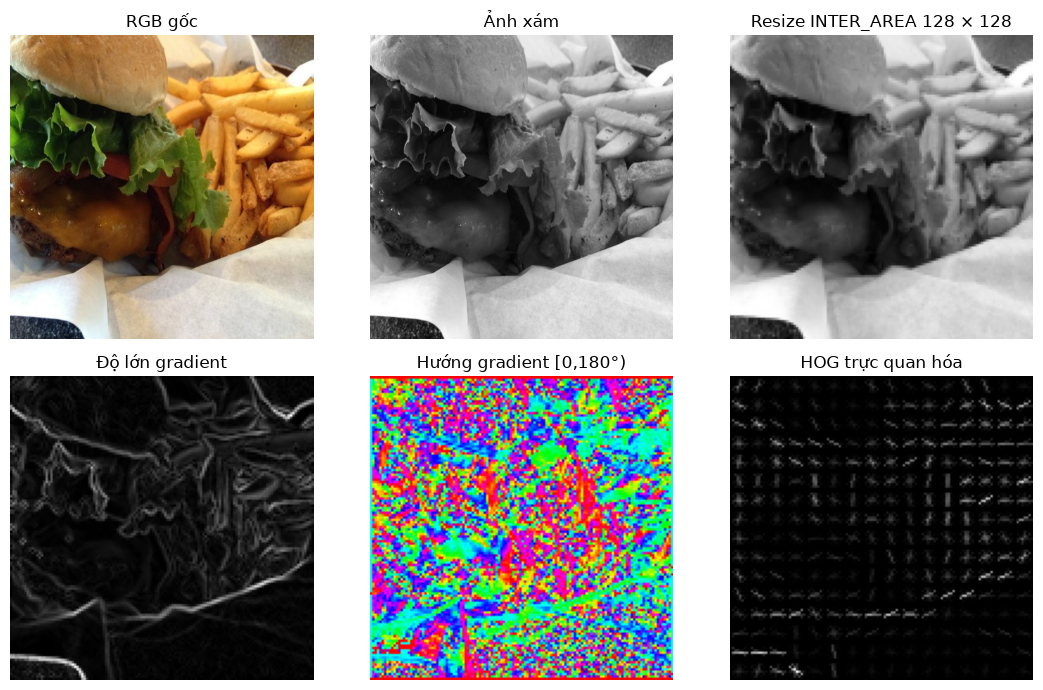

Kích thước vector HOG: (8100,) | 15×15 block × 2×2 cell × 9 hướng = 8100
Vector visualize tương đương extract_hog: PASS (khớp chính xác)


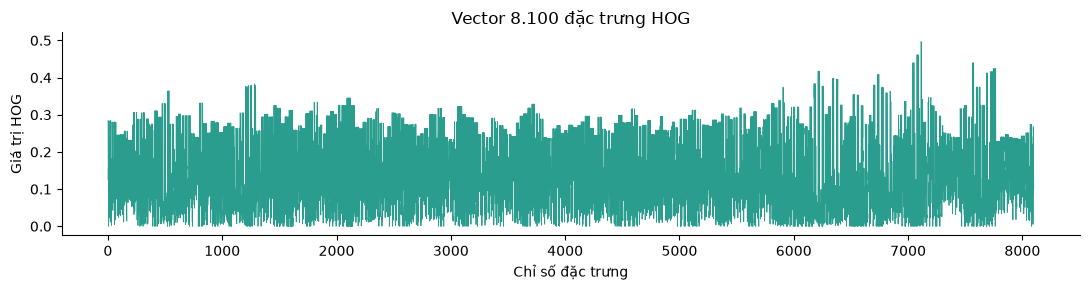

In [10]:
feature = extract_hog(rgb, hog_config)
options = hog_config["hog"]
visual_feature, hog_image = hog(resized_hog, orientations=options["orientations"],
    pixels_per_cell=tuple(options["pixels_per_cell"]),
    cells_per_block=tuple(options["cells_per_block"]), block_norm="L2-Hys", visualize=True)
np.testing.assert_array_equal(feature, visual_feature)
expected_features = (128 // 8 - 2 + 1) ** 2 * 2 * 2 * 9
assert feature.shape == (expected_features,) and expected_features == 8100
floating = resized_hog.astype(np.float64)
grad_y, grad_x = np.zeros_like(floating), np.zeros_like(floating)
grad_y[1:-1, :] = floating[2:, :] - floating[:-2, :]
grad_x[:, 1:-1] = floating[:, 2:] - floating[:, :-2]
magnitude = np.hypot(grad_x, grad_y)
orientation = np.rad2deg(np.arctan2(grad_y, grad_x)) % 180
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
panels = [(rgb, "RGB gốc", None), (gray, "Ảnh xám", "gray"),
          (resized_hog, "Resize INTER_AREA 128 × 128", "gray"),
          (magnitude, "Độ lớn gradient", "gray"), (orientation, "Hướng gradient [0,180°)", "hsv"),
          (exposure.rescale_intensity(hog_image, out_range=(0, 1)), "HOG trực quan hóa", "gray")]
for ax, (array, label, cmap) in zip(axes.flat, panels):
    ax.imshow(array, cmap=cmap); ax.set_title(label); ax.axis("off")
finish(fig, "10_gradient_hog.png")
print("Kích thước vector HOG:", feature.shape, "| 15×15 block × 2×2 cell × 9 hướng = 8100")
print("Vector visualize tương đương extract_hog: PASS (khớp chính xác)")
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(feature, linewidth=.6, color="#2a9d8f")
ax.set(title="Vector 8.100 đặc trưng HOG", xlabel="Chỉ số đặc trưng", ylabel="Giá trị HOG")
finish(fig, "11_vector_hog.png")

## 5. Nhận dạng cổ điển HOG + SVM
**Mục tiêu:** nối các phép xử lý ảnh với một bộ phân loại thực tế.
StandardScaler và LinearSVC đã được fit ở giai đoạn trước. Notebook chỉ nạp
checkpoint HOG đã có, xác minh checksum và dự đoán 4 ảnh validation minh họa.
Không gọi `.fit`, không tìm C mới và không biến các dự đoán này thành accuracy test.

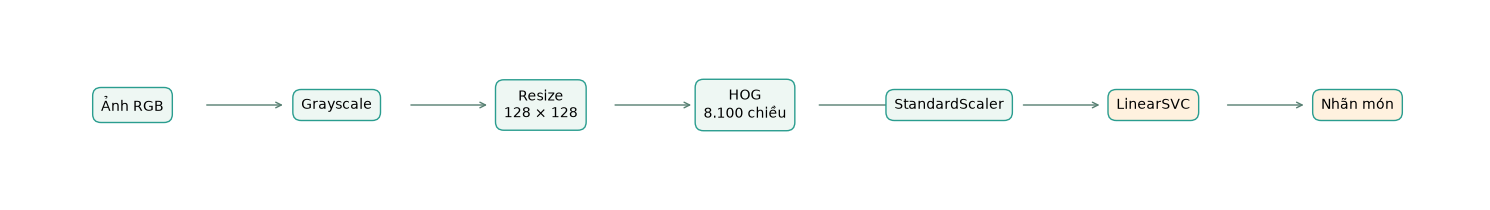

,Ảnh validation,Nhãn thật,Nhãn HOG + SVM dự đoán
0,hamburger/1010695,hamburger,ice_cream
1,ice_cream/102595,ice_cream,apple_pie
2,pizza/1040878,pizza,apple_pie
3,chicken_curry/104874,chicken_curry,apple_pie


Không tính accuracy từ 4 ảnh minh họa; không có training mới.


In [11]:
stages = ["Ảnh RGB", "Grayscale", "Resize\n128 × 128", "HOG\n8.100 chiều",
          "StandardScaler", "LinearSVC", "Nhãn món"]
fig, ax = plt.subplots(figsize=(15, 2.2))
ax.set(xlim=(-.6, 6.6), ylim=(-.6, .6)); ax.axis("off")
for i, label in enumerate(stages):
    ax.text(i, 0, label, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=.6", facecolor="#eef7f3" if i < 5 else "#fff1df",
                      edgecolor="#2a9d8f"))
    if i < len(stages)-1:
        ax.annotate("", xy=(i+.75, 0), xytext=(i+.35, 0), arrowprops=dict(arrowstyle="->", color="#567f71"))
finish(fig, "12_pipeline_hog_svm.png")
checksums = json.loads((hog_dir / "checksum.sha256").read_text(encoding="utf-8"))
assert digest(hog_dir / "model.joblib") == checksums["model.joblib"]
classifier = joblib.load(hog_dir / "model.joblib")  # Chỉ artifact cục bộ đã xác minh của dự án
assert [type(step).__name__ for step in classifier.named_steps.values()] == ["StandardScaler", "LinearSVC"]
assert classifier.n_features_in_ == len(feature)
scaler = next(iter(classifier.named_steps.values()))
assert hasattr(scaler, "mean_") and hasattr(scaler, "scale_")
labels = json.loads((hog_dir / "labels.json").read_text(encoding="utf-8"))["labels"]
rows = []
for sample in samples:
    vector = extract_hog(sample["rgb"], hog_config)
    predicted_id = int(classifier.predict(vector[None, :])[0])
    rows.append({"Ảnh validation": sample["image_id"], "Nhãn thật": sample["class_key"],
                 "Nhãn HOG + SVM dự đoán": labels[predicted_id]["class_key"]})
display(pd.DataFrame(rows))
print("Không tính accuracy từ 4 ảnh minh họa; không có training mới.")

In [12]:
comparison_path = ROOT / "artifacts/reports/experiment_comparison.csv"
comparison = pd.read_csv(comparison_path)
saved_metrics = {}
for name, directory in releases.items():
    metrics = json.loads((directory / "metrics_test.json").read_text(encoding="utf-8"))
    config = json.loads((directory / "model_config.json").read_text(encoding="utf-8"))
    assert config["trained"] and not config["smoke_only"]
    assert metrics["split"] == "test" and metrics["sample_count"] == 2500
    assert metrics["num_classes"] == 10 and metrics["device"] == "cpu"
    assert metrics["manifest_sha256"] == digest(manifest_dir / "dataset_manifest.csv")
    row = comparison[(comparison.model_name == name) & (comparison.run_id == metrics["run_id"])]
    assert len(row) == 1, "Báo cáo so sánh thiếu/trùng model"
    for key in ["top1_accuracy", "macro_f1", "p50_ms", "p95_ms"]:
        np.testing.assert_allclose(row.iloc[0][key], metrics[key], rtol=0, atol=1e-12)
    saved_metrics[name] = metrics
hog_metrics = saved_metrics["hog_svm"]
display(pd.DataFrame([{key: hog_metrics[key] for key in
    ["top1_accuracy", "macro_precision", "macro_recall", "macro_f1", "sample_count", "p50_ms", "p95_ms"]}]))
display(Markdown(f"**Kết quả đã lưu của HOG + SVM:** Accuracy **{hog_metrics['top1_accuracy']*100:.2f}%**, "
    f"Macro-F1 **{hog_metrics['macro_f1']:.4f}**, trên {hog_metrics['sample_count']} ảnh test POC. "
    "Notebook chỉ đọc JSON/CSV báo cáo, không đọc lại ảnh test hay chạy Evaluate."))

,top1_accuracy,macro_precision,macro_recall,macro_f1,sample_count,p50_ms,p95_ms
0,0.1876,0.188871,0.1876,0.187031,2500,5.0842,5.76292


**Kết quả đã lưu của HOG + SVM:** Accuracy **18.76%**, Macro-F1 **0.1870**, trên 2500 ảnh test POC. Notebook chỉ đọc JSON/CSV báo cáo, không đọc lại ảnh test hay chạy Evaluate.

**Nhận xét HOG + SVM:** HOG mã hóa cấu trúc gradient và bỏ thông tin màu sau chuyển xám.
Món ăn có biến thiên góc chụp, cách trình bày, topping, nền và kết cấu; nhiều lớp không
có hình dạng cố định. Resize vuông cũng có thể làm biến dạng tỷ lệ. Đây là các khả năng
giải thích baseline thấp, **chưa phải kết luận nhân quả đã được kiểm chứng bằng ablation**.
Lỗi từng ảnh validation ở trên chỉ là minh họa, không thay thế confusion matrix đã lưu.

## 6. So sánh với Deep Learning bằng kết quả thực nghiệm đã lưu
**Mục tiêu:** so sánh mô hình trên cùng bộ nhãn và tập đánh giá đã chốt.
HOG + SVM dùng đặc trưng thủ công; ResNet18/EfficientNet-B0 học đặc trưng bằng CNN.
Chỉ đọc bảng trong `artifacts/reports/experiment_comparison.csv` và đối chiếu JSON
ở từng release. Không tạo lại Accuracy/Macro-F1 hoặc đo latency mới trong notebook.

Latency là số đo CPU đã lưu, batch 1, p50/p95, gồm preprocessing + inference nhưng
**không gồm giải mã file**; không phải thời gian toàn bộ request web hoặc tốc độ GPU.

,Mô hình,Accuracy (%),Macro-F1,p50 CPU (ms/ảnh),p95 CPU (ms/ảnh),Số ảnh test đã đánh giá
0,HOG + SVM,18.76,0.1870,5.0842,5.7629,2500
1,ResNet18,89.76,0.8975,27.3837,29.8499,2500
2,EfficientNet-B0,89.80,0.8970,18.2808,20.3333,2500


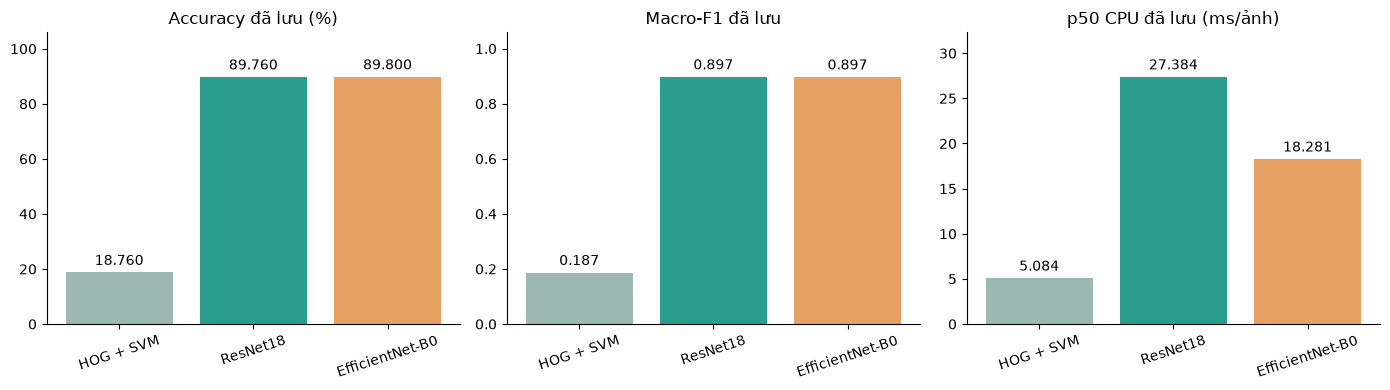

**Nhận xét:** CNN có kết quả cao hơn baseline HOG trên thí nghiệm đã lưu. Chênh Accuracy giữa hai CNN chỉ 0,04 điểm phần trăm; chưa có kiểm định để khẳng định một kiến trúc luôn tốt hơn. EfficientNet-B0 production được chọn theo quy trình validation đã có, không dùng lại test để điều chỉnh mô hình. Bộ lọc/HSV/Lab trong notebook không được dùng để huấn luyện lại các mô hình này.

In [13]:
names = {"hog_svm": "HOG + SVM", "resnet18": "ResNet18", "efficientnet_b0": "EfficientNet-B0"}
summary = pd.DataFrame([{
    "Mô hình": names[name], "Accuracy (%)": saved_metrics[name]["top1_accuracy"] * 100,
    "Macro-F1": saved_metrics[name]["macro_f1"],
    "p50 CPU (ms/ảnh)": saved_metrics[name]["p50_ms"],
    "p95 CPU (ms/ảnh)": saved_metrics[name]["p95_ms"],
    "Số ảnh test đã đánh giá": saved_metrics[name]["sample_count"],
} for name in ["hog_svm", "resnet18", "efficientnet_b0"]])
display(summary.round(4))
summary.to_csv(OUT / "saved_model_comparison.csv", index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, key, title in zip(axes, ["Accuracy (%)", "Macro-F1", "p50 CPU (ms/ảnh)"],
                         ["Accuracy đã lưu (%)", "Macro-F1 đã lưu", "p50 CPU đã lưu (ms/ảnh)"]):
    bars = ax.bar(summary["Mô hình"], summary[key], color=["#9bb9b0", "#2a9d8f", "#e8a165"])
    ax.set_title(title); ax.tick_params(axis="x", labelrotation=18)
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.margins(y=.18)
finish(fig, "13_so_sanh_mo_hinh.png")
display(Markdown("**Nhận xét:** CNN có kết quả cao hơn baseline HOG trên thí nghiệm đã lưu. "
    "Chênh Accuracy giữa hai CNN chỉ 0,04 điểm phần trăm; chưa có kiểm định để khẳng định "
    "một kiến trúc luôn tốt hơn. EfficientNet-B0 production được chọn theo quy trình "
    "validation đã có, không dùng lại test để điều chỉnh mô hình. "
    "Bộ lọc/HSV/Lab trong notebook không được dùng để huấn luyện lại các mô hình này."))

## 7. Tổng kết báo cáo giữa kỳ
**Đã áp dụng thực tế:** kiểm tra/giải mã ảnh, sửa EXIF và RGB; RGB → grayscale;
INTER_AREA 128×128; HOG 9 hướng, cell 8×8, block 2×2, L2-Hys; StandardScaler và
LinearSVC; CNN có resize/crop, tăng cường crop/lật ngang ở training và Normalize ImageNet.

**Bổ sung minh họa:** tách kênh, HSV/Lab, histogram; so sánh miền pixel; nhiễu nhân tạo,
Gaussian/Median Filter, MSE/PSNR/SSIM; gradient và trực quan hóa HOG. Những bước này
không tự động trở thành tiền xử lý production.

**Phạm vi còn thiếu:** chưa làm phân đoạn, SIFT hoặc phép hình thái erosion/dilation/
opening/closing. Đồ án hiện chọn hướng nhận dạng cổ điển HOG theo yêu cầu “ít nhất một
trong hai hướng”; hình thái phù hợp khi mở rộng xử lý biên/vùng. Chưa có ablation để kết
luận lọc nhiễu cải thiện nhận dạng. Chưa đánh giá 101 lớp, ảnh món Việt hay nhiều món/ảnh.

**Hạn chế:** chỉ 4 ảnh validation dùng minh họa, không đại diện toàn dataset. Metric khử
nhiễu dùng ảnh tham chiếu và nhiễu tổng hợp; không khẳng định phục hồi ảnh thực. Kết quả
10 lớp không suy rộng thành kết quả 101 lớp. Nhận diện món không đo được gram bằng ảnh 2D.

**Hướng phát triển:** mở rộng dữ liệu/nhãn có kiểm soát, giữ test độc lập; so sánh đặc trưng
màu/kết cấu hoặc tiền xử lý bằng train/validation; đánh giá đa lớp và ảnh thực khi có nguồn lực.
Mọi thay đổi tiền xử lý mô hình cần thí nghiệm và phiên bản mới, không ghi đè release đang chạy.

Báo cáo/slide có thể dùng hình 01–13 và hai bảng CSV bên dưới. Trình bày rõ phạm vi giữa kỳ,
nêu các kỹ thuật đã dùng, kỹ thuật minh họa và phần chưa thực hiện; không gọi đây là nghiên
cứu phân đoạn hoặc đo khẩu phần tự động từ ảnh.

In [14]:
after_hashes = {name: digest(ROOT / name) for name in before_hashes}
assert before_hashes == after_hashes, "Một file được bảo vệ đã thay đổi"
assert all(s["split"] == "val" for s in samples) and len(samples) == 4
assert len(exported) == 13 and all((ROOT / name).is_file() for name in exported)
report = {"status": "PASS", "seed": SEED, "device": "cpu", "training_performed": False,
    "test_evaluation_performed": False, "test_images_opened": 0,
    "sample_count": len(samples), "sample_splits": sorted({s["split"] for s in samples}),
    "samples": [{k: s[k] for k in ("image_id", "relative_path", "class_key", "split", "checksum")}
                for s in samples],
    "hog_features": len(feature), "hog_visualization_matches_pipeline": True,
    "cnn_normalization_matches_pipeline": True, "noise_repeatable": True,
    "protected_files_unchanged": True, "figures": exported,
    "python_version": platform.python_version(),
    "selection_note": "Hamburger 1010695 selected by visual content, not prediction; other classes first sorted val sample",
    "metric_sources": {name: {"run_id": metrics["run_id"],
                        "path": str((releases[name] / "metrics_test.json").relative_to(ROOT)),
                        "sha256": digest(releases[name] / "metrics_test.json")}
                       for name, metrics in saved_metrics.items()},
    "libraries": {"opencv": cv2.__version__, "numpy": np.__version__,
                  "matplotlib": matplotlib.__version__, "torch": torch.__version__}}
(OUT / "execution_summary.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame({"Hình PNG đã xuất (300 dpi)": exported}))
print("PASS: 4 ảnh validation, 13 hình, không huấn luyện, không Evaluate lại, file bảo vệ giữ nguyên.")
print("Các bảng: noise_metrics.csv, saved_model_comparison.csv; kiểm chứng: execution_summary.json")
print("Thư mục kết quả:", OUT)

,Hình PNG đã xuất (300 dpi)
0,artifacts\reports\midterm_visualizations\run_2...
1,artifacts\reports\midterm_visualizations\run_2...
2,artifacts\reports\midterm_visualizations\run_2...
3,artifacts\reports\midterm_visualizations\run_2...
4,artifacts\reports\midterm_visualizations\run_2...
5,artifacts\reports\midterm_visualizations\run_2...
6,artifacts\reports\midterm_visualizations\run_2...
7,artifacts\reports\midterm_visualizations\run_2...
8,artifacts\reports\midterm_visualizations\run_2...
9,artifacts\reports\midterm_visualizations\run_2...


PASS: 4 ảnh validation, 13 hình, không huấn luyện, không Evaluate lại, file bảo vệ giữ nguyên.
Các bảng: noise_metrics.csv, saved_model_comparison.csv; kiểm chứng: execution_summary.json
Thư mục kết quả: d:\food-recognition-dietary-assistant\food-recognition-dietary-assistant\artifacts\reports\midterm_visualizations\run_20261031T150720_680002Z
